# Telco Customer Churn Prediction — CM2604 Machine Learning Coursework

**Task:** binary classification (churn vs. stay) using **KNN**, **Logistic Regression** and **Random Forest**.

## 1. Setup & Configuration

In [26]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
IMG_DIR, RES_DIR = "images", "results"
for d in (IMG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

# Put the Kaggle CSV in one of these locations
CANDIDATES = ["data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
              "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
              "WA_Fn-UseC_-Telco-Customer-Churn.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place WA_Fn-UseC_-Telco-Customer-Churn.csv in ./data/")
print("Using dataset:", DATA_PATH)

Using dataset: ../data/WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Data Loading & Overview
First look at the raw data: size, data types, summary statistics, missing values and duplicates.

In [27]:
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [28]:
display(df.describe())
print("Nulls per column:\n", df.isnull().sum()[lambda s: s > 0])
print("Duplicate rows:", df.duplicated().sum())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Nulls per column:
 Series([], dtype: int64)
Duplicate rows: 0


## 3. Data Cleaning
* `TotalCharges` is stored as text because 11 rows contain a blank string → convert to numeric. These are brand-new customers (`tenure = 0`), so `0` is the correct fill value.
* `customerID` is a unique identifier with no predictive value → drop.
* `"No phone service"` / `"No internet service"` carry the same information as `"No"` (already captured by `PhoneService` / `InternetService`) → merge into `"No"`.
* Create a numeric target `Churn_bin` (1 = churned).

In [29]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isnull().sum(), "(expect 11)")
print("Their tenure values:", df.loc[df["TotalCharges"].isnull(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df = df.replace({"No phone service": "No", "No internet service": "No"})
df["Churn_bin"] = (df["Churn"] == "Yes").astype(int)

print("Duplicates after dropping customerID:", df.duplicated().sum())
print("Remaining nulls:", df.isnull().sum().sum())

Blank TotalCharges: 11 (expect 11)
Their tenure values: [0]
Duplicates after dropping customerID: 22
Remaining nulls: 0


## 4. Exploratory Data Analysis (Task 1)

### 4.1 Target distribution (class imbalance)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


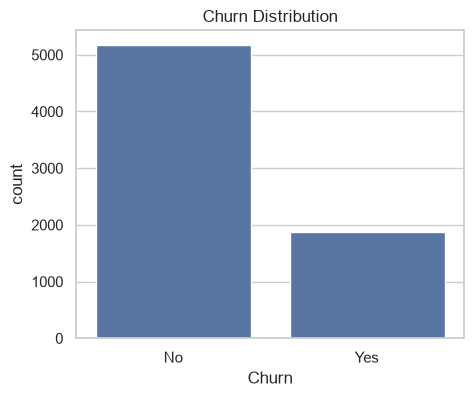

In [30]:
print(df["Churn"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.savefig(f"{IMG_DIR}/churn_distribution.png", bbox_inches="tight")
plt.show()

### 4.2 Numeric features vs. churn

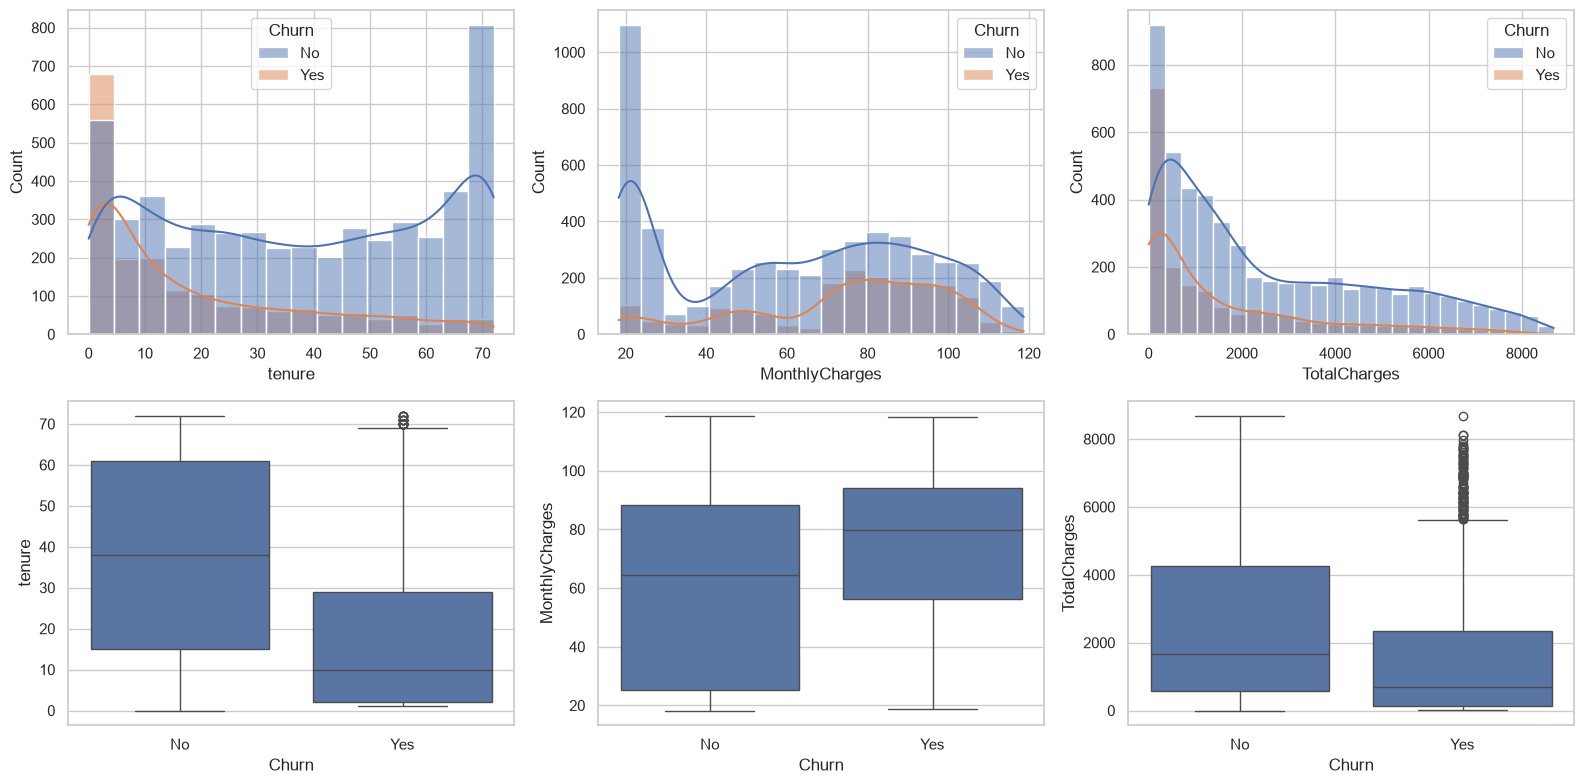

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [31]:
num_cols_eda = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols_eda):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[0, i])
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[1, i])
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/numeric_vs_churn.png", bbox_inches="tight")
plt.show()

display(df.groupby("Churn")[num_cols_eda].agg(["mean", "median"]).round(2))

### 4.3 Categorical features vs. churn rate

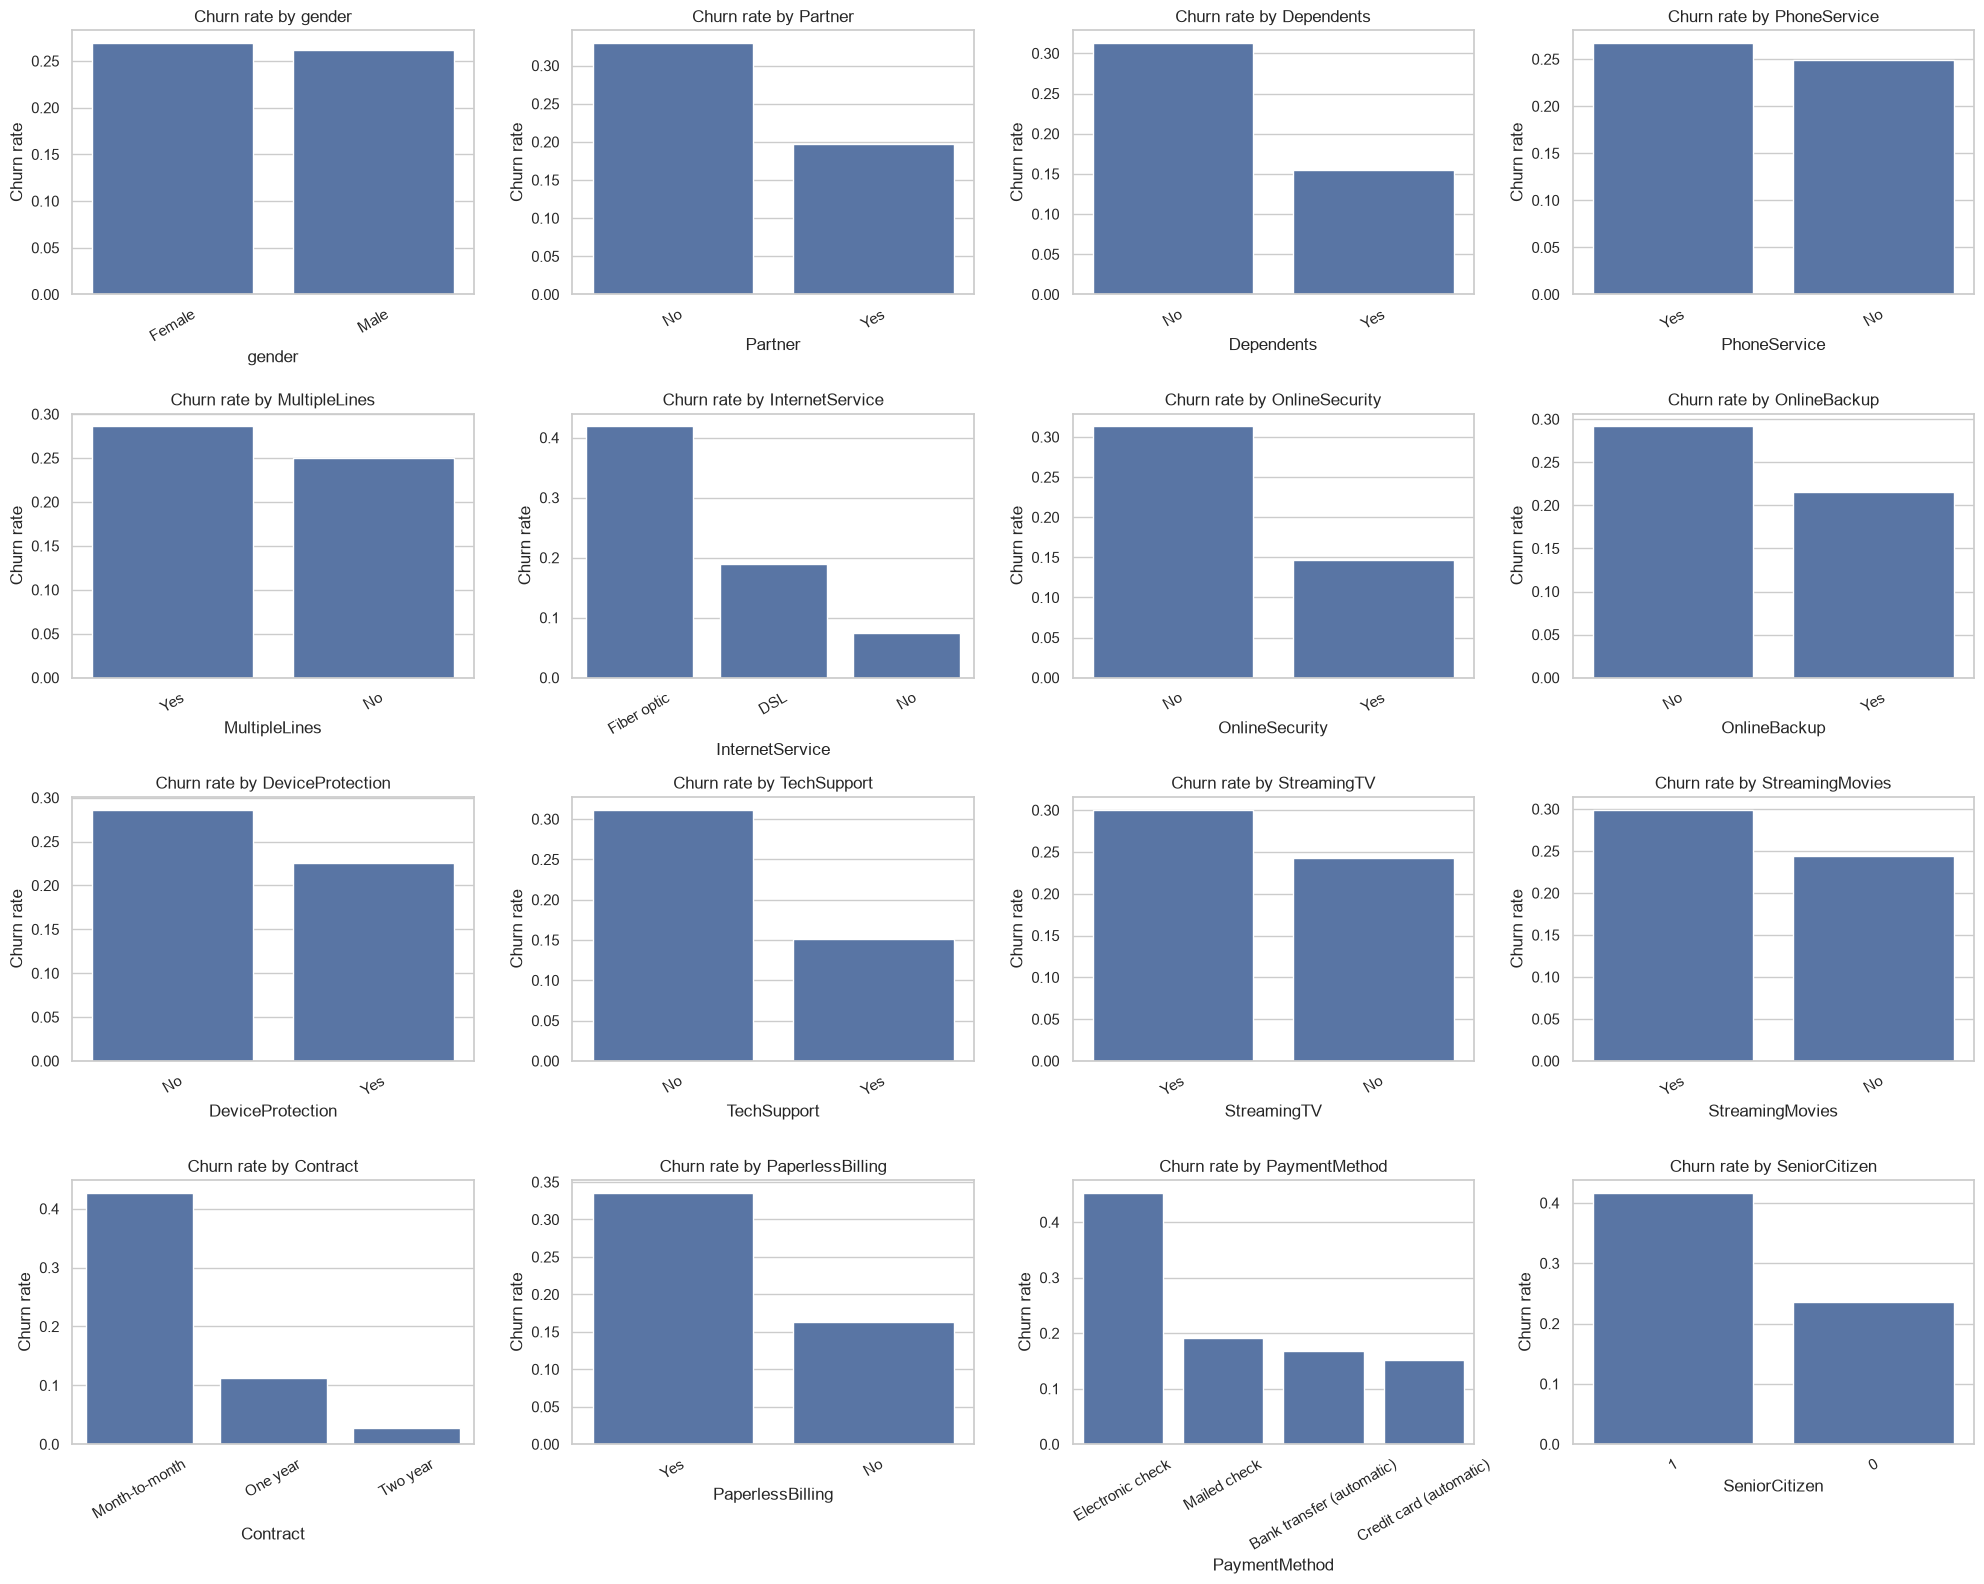

In [32]:
cat_cols_eda = [c for c in df.select_dtypes("object").columns if c != "Churn"] + ["SeniorCitizen"]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()
for i, col in enumerate(cat_cols_eda):
    rate = df.groupby(col)["Churn_bin"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[i])
    axes[i].set_title(f"Churn rate by {col}")
    axes[i].set_ylabel("Churn rate")
    axes[i].tick_params(axis="x", rotation=30)
for j in range(len(cat_cols_eda), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/categorical_vs_churn.png", bbox_inches="tight")
plt.show()

### 4.4 Correlation analysis

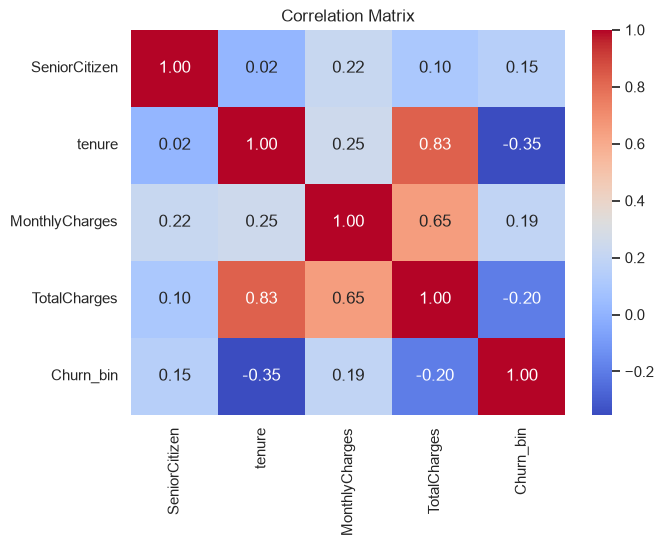

In [33]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.savefig(f"{IMG_DIR}/correlation_heatmap.png", bbox_inches="tight")
plt.show()

### 4.5 Key churn drivers (numbers to quote in the report)

In [34]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["Churn_bin"].mean().sort_values(ascending=False).round(3), "\n")

tenure_group = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
print(df.groupby(tenure_group, observed=True)["Churn_bin"].mean().round(3))

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn_bin, dtype: float64 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn_bin, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn_bin, dtype: float64 

tenure
0-12     0.474
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn_bin, dtype: float64


**Insights to document in your report** *(fill in after running — check the numbers above and the plots)*:
* Class imbalance → accuracy alone is misleading; use ROC-AUC, recall, F1.
* Customers on **month-to-month contracts** and with **short tenure** churn most.
* **Fibre-optic** customers and **electronic-check** payers show higher churn.
* Churners tend to have **higher monthly charges** but **lower total charges** (they leave early).
* `TotalCharges` is strongly correlated with `tenure` (multicollinearity — relevant for Logistic Regression).

## 5. Feature Engineering & Preprocessing

### 5.1 Feature engineering
`n_services` counts how many optional add-on services a customer has — a simple measure of how "locked-in" they are.

### 5.2 Train / test split
The split happens **before** any fitting of scalers/encoders, so no information from the test set leaks into training. Stratification keeps the churn ratio equal in both sets.

In [35]:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
df["n_services"] = (df[addon_cols] == "Yes").sum(axis=1)

X = df.drop(columns=["Churn", "Churn_bin"])     # drop BOTH target columns -> no leakage
y = df["Churn_bin"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5634, 20) | Test: (1409, 20)
Churn rate  train: 0.265 | test: 0.265


### 5.3 Preprocessing pipeline
* **Numeric** → `StandardScaler` (essential for KNN's distance metric and for regularised Logistic Regression).
* **Categorical** → `OneHotEncoder(drop="first")` (avoids the dummy-variable trap for Logistic Regression).
* Wrapped in a `Pipeline` so scaling/encoding is re-fitted **inside each CV fold**.

In [36]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "n_services"]
cat_cols = [c for c in X.columns if c not in num_cols]

def build_preprocess(num, cat):
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ])

preprocess = build_preprocess(num_cols, cat_cols)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_services']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6. Baseline Models (default hyper-parameters, 5-fold stratified CV)
Establishes a reference point before tuning. Scores are on the **training set only**.

In [37]:
baseline_models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}
scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

rows = []
for name, model in baseline_models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{k: s[f"test_{k}"].mean() for k in scoring}})

baseline_df = pd.DataFrame(rows).set_index("Model").round(3)
display(baseline_df)

,roc_auc,f1,recall,precision,accuracy
Model,,,,,
KNN,0.781,0.550,0.534,0.567,0.768
Logistic Regression,0.846,0.593,0.543,0.655,0.803
Random Forest,0.823,0.548,0.481,0.638,0.789


## 7. Hyperparameter Tuning
* **KNN** and **Logistic Regression** → `GridSearchCV` (small search spaces).
* **Random Forest** → `RandomizedSearchCV` (larger space, 25 random combinations).
* Scoring: **ROC-AUC** is the refit metric (threshold-independent and robust to imbalance); F1, recall and precision are tracked too.
* All searches use the same stratified 5-fold CV on the **training set**; the test set stays untouched.

In [38]:
search_scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

searches = {
    "KNN": GridSearchCV(
        make_pipe(KNeighborsClassifier()),
        {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41],
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
        cv=cv, scoring=search_scoring, refit="roc_auc", n_jobs=-1),

    "Logistic Regression": GridSearchCV(
        make_pipe(LogisticRegression(max_iter=2000)),
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100],
         "model__class_weight": [None, "balanced"]},
        cv=cv, scoring=search_scoring, refit="roc_auc", n_jobs=-1),

    "Random Forest": RandomizedSearchCV(
        make_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
        {"model__n_estimators": [200, 300, 500],
         "model__max_depth": [None, 5, 8, 12, 16],
         "model__min_samples_leaf": [1, 2, 5, 10],
         "model__max_features": ["sqrt", "log2", 0.3],
         "model__class_weight": [None, "balanced", "balanced_subsample"]},
        n_iter=25, cv=cv, scoring=search_scoring, refit="roc_auc",
        n_jobs=1, random_state=RANDOM_STATE),
}

best_models, tuning_rows = {}, []
for name, search in searches.items():
    print(f"Tuning {name} ...")
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    i = search.best_index_
    r = search.cv_results_
    tuning_rows.append({
        "Model": name,
        "Best params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "CV ROC-AUC": r["mean_test_roc_auc"][i], "CV F1": r["mean_test_f1"][i],
        "CV Recall": r["mean_test_recall"][i], "CV Precision": r["mean_test_precision"][i]})

tuning_df = pd.DataFrame(tuning_rows).set_index("Model")
pd.set_option("display.max_colwidth", 120)
display(tuning_df.round(3))

Tuning KNN ...
Tuning Logistic Regression ...
Tuning Random Forest ...


,Best params,CV ROC-AUC,CV F1,CV Recall,CV Precision
Model,,,,,
KNN,"{'n_neighbors': 41, 'p': 1, 'weights': 'uniform'}",0.837,0.602,0.575,0.632
Logistic Regression,"{'C': 100, 'class_weight': None}",0.846,0.597,0.550,0.655
Random Forest,"{'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': 8, 'class_weight': 'balanced'}",0.847,0.630,0.783,0.527


### 7.1 Effect of KNN's *k* (bias–variance illustration)

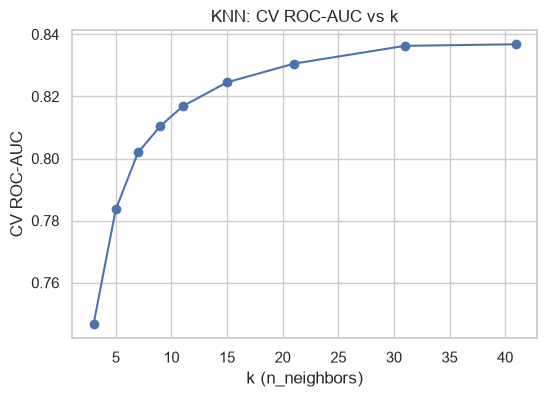

In [39]:
knn_res = pd.DataFrame(searches["KNN"].cv_results_)
knn_res = knn_res[(knn_res["param_model__weights"] == searches["KNN"].best_params_["model__weights"]) &
                  (knn_res["param_model__p"] == searches["KNN"].best_params_["model__p"])]
plt.figure(figsize=(6, 4))
plt.plot(knn_res["param_model__n_neighbors"], knn_res["mean_test_roc_auc"], marker="o")
plt.xlabel("k (n_neighbors)"); plt.ylabel("CV ROC-AUC"); plt.title("KNN: CV ROC-AUC vs k")
plt.savefig(f"{IMG_DIR}/knn_k_curve.png", bbox_inches="tight")
plt.show()

## 8. Final Evaluation & Model Comparison (held-out test set)
Tuned models are evaluated **once** on the untouched 20 % test set, at the default 0.5 threshold.

In [40]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba)}, proba, pred

test_rows, probas, preds = {}, {}, {}
for name, model in best_models.items():
    test_rows[name], probas[name], preds[name] = evaluate(model, X_test, y_test)

test_df = pd.DataFrame(test_rows).T.round(3)
display(test_df)
test_df.to_csv(f"{RES_DIR}/test_metrics_threshold_0.5.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC
KNN,0.785,0.601,0.564,0.582,0.831
Logistic Regression,0.802,0.650,0.551,0.596,0.841
Random Forest,0.757,0.528,0.794,0.635,0.846


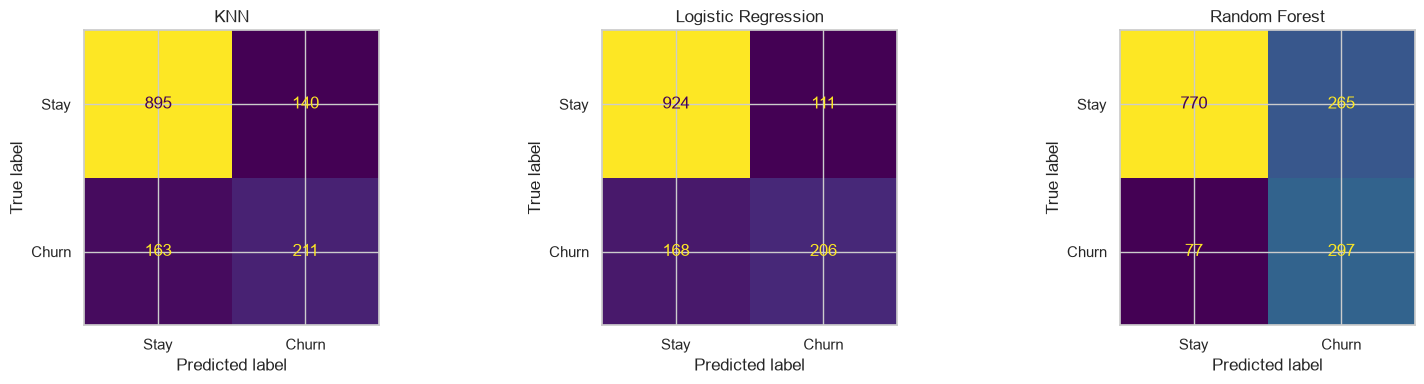

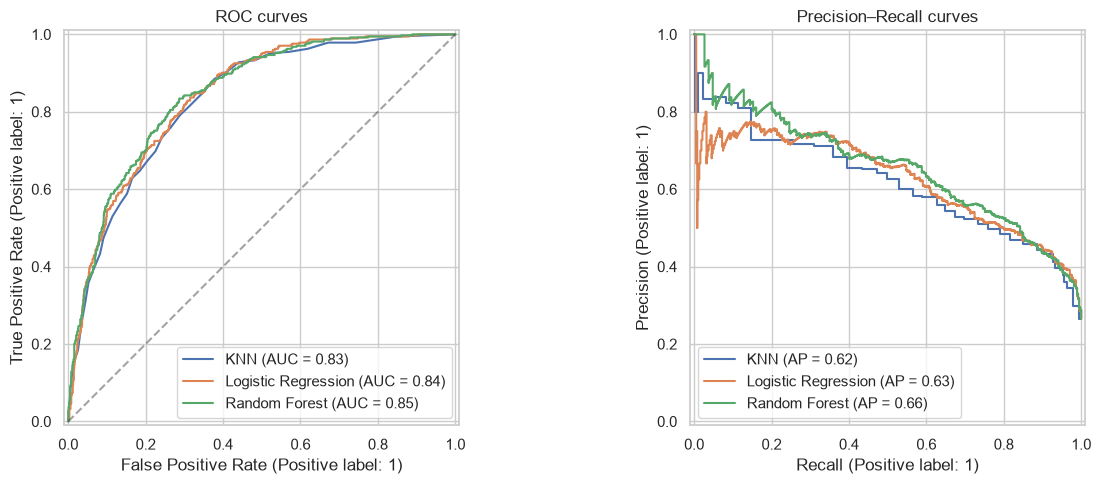

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stay", "Churn"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/confusion_matrices.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curves"); axes[1].set_title("Precision–Recall curves")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/roc_pr_comparison.png", bbox_inches="tight")
plt.show()

In [42]:
for name, pred in preds.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Stay", "Churn"]))

===== KNN =====
              precision    recall  f1-score   support

        Stay       0.85      0.86      0.86      1035
       Churn       0.60      0.56      0.58       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.72      1409
weighted avg       0.78      0.78      0.78      1409

===== Logistic Regression =====
              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1035
       Churn       0.65      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

===== Random Forest =====
              precision    recall  f1-score   support

        Stay       0.91      0.74      0.82      1035
       Churn       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409


In [43]:
# Best model is chosen by CROSS-VALIDATION score (not by test score) to avoid test-set selection bias
best_name = tuning_df["CV ROC-AUC"].idxmax()
best_model = best_models[best_name]
print("Selected model:", best_name)

Selected model: Random Forest


## 9. Decision Threshold Optimisation
Because only ~27 % of customers churn, 0.5 is rarely the best cut-off. The F1-optimal threshold is chosen from **out-of-fold predictions on the training set** (never from the test set, which would be data leakage), then applied once to the test set.

In [44]:
thr_rows, thresholds = {}, {}
for name, model in best_models.items():
    oof = cross_val_predict(clone(model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    thresholds[name] = float(thr[np.argmax(f1s)])
    m, _, _ = evaluate(model, X_test, y_test, threshold=thresholds[name])
    thr_rows[name] = {"Threshold": thresholds[name], **m}

thr_df = pd.DataFrame(thr_rows).T.round(3)
display(thr_df)
thr_df.to_csv(f"{RES_DIR}/test_metrics_tuned_threshold.csv")

print("\nTuned-threshold report for", best_name)
_, _, best_pred = evaluate(best_model, X_test, y_test, thresholds[best_name])
print(classification_report(y_test, best_pred, target_names=["Stay", "Churn"]))

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
KNN,0.366,0.752,0.523,0.733,0.610,0.831
Logistic Regression,0.319,0.755,0.528,0.725,0.611,0.841
Random Forest,0.545,0.768,0.546,0.751,0.632,0.846



Tuned-threshold report for Random Forest
              precision    recall  f1-score   support

        Stay       0.90      0.77      0.83      1035
       Churn       0.55      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



## 10. Model Interpretation
Which features drive churn? Logistic Regression coefficients (direction + size) and Random Forest importances (size only).

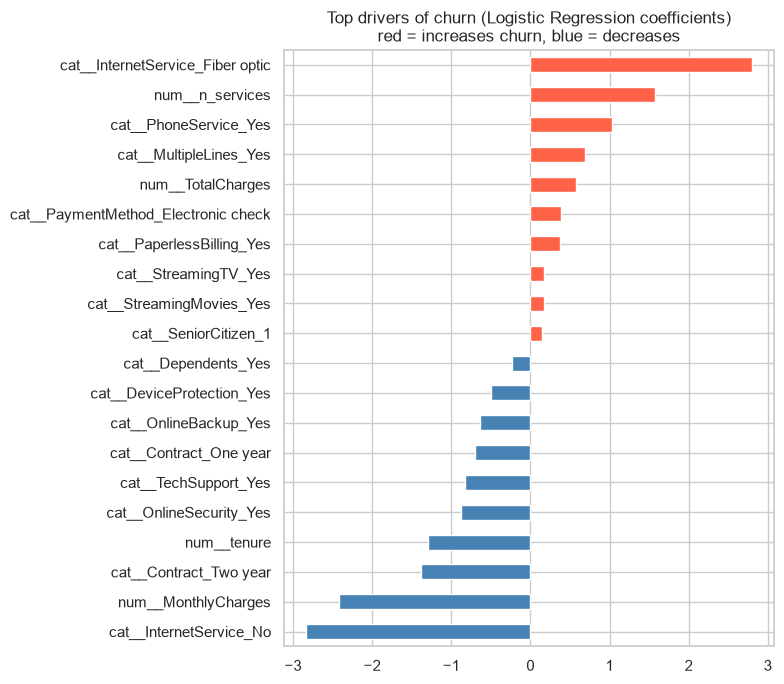

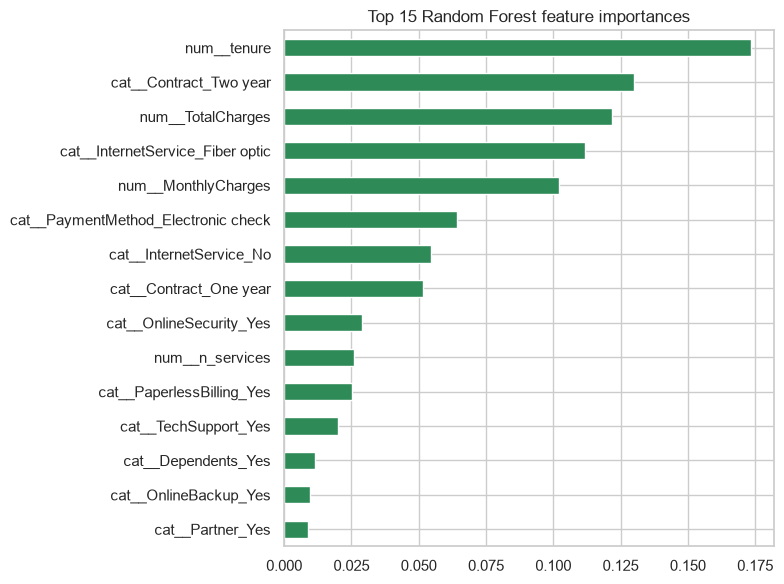

In [45]:
feat_names = best_models["Logistic Regression"].named_steps["prep"].get_feature_names_out()

coefs = pd.Series(best_models["Logistic Regression"].named_steps["model"].coef_[0], index=feat_names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(8, 7))
top.plot(kind="barh", color=np.where(top > 0, "tomato", "steelblue"))
plt.title("Top drivers of churn (Logistic Regression coefficients)\nred = increases churn, blue = decreases")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/lr_coefficients.png", bbox_inches="tight")
plt.show()

rf_imp = pd.Series(best_models["Random Forest"].named_steps["model"].feature_importances_,
                   index=best_models["Random Forest"].named_steps["prep"].get_feature_names_out()
                   ).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
rf_imp[::-1].plot(kind="barh", color="seagreen")
plt.title("Top 15 Random Forest feature importances")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/rf_importance.png", bbox_inches="tight")
plt.show()

## 11. AI Ethics: Fairness Audit (Task 3)

### 11.1 Ethical strategies applied during development
| Principle | What was done in this project |
|-----------|-------------------------------|
| **Privacy / data minimisation** | `customerID` removed; no names, addresses or contact details used. |
| **No leakage / validity** | Split before preprocessing; threshold and model chosen on training data only. |
| **Sensitive attributes** | `gender` and `SeniorCitizen` (age proxy) are protected characteristics → audited below. |
| **Fairness testing** | Per-group selection rate, recall and false-positive rate compared (below). |
| **Transparency / explainability** | Interpretable baseline (Logistic Regression) + feature importances reported. |
| **Reproducibility** | Fixed seeds, Git-tracked code, saved pipeline. |
| **Imbalance handling** | `class_weight` + threshold tuning so minority (churn) customers are not ignored. |

### 11.2 Subgroup fairness audit

In [46]:
def group_metrics(df_test, y_true, y_pred, group_col):
    rows = []
    for g, idx in df_test.groupby(group_col).groups.items():
        yt, yp = y_true.loc[idx], pd.Series(y_pred, index=y_true.index).loc[idx]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append({group_col: g, "n": len(idx), "Actual churn rate": yt.mean(),
                     "Predicted churn rate": yp.mean(),
                     "Recall (TPR)": tp / (tp + fn) if (tp + fn) else np.nan,
                     "False-positive rate": fp / (fp + tn) if (fp + tn) else np.nan,
                     "Precision": tp / (tp + fp) if (tp + fp) else np.nan})
    out = pd.DataFrame(rows).set_index(group_col)
    out["Selection-rate ratio (vs max)"] = out["Predicted churn rate"] / out["Predicted churn rate"].max()
    return out.round(3)

for col in ["gender", "SeniorCitizen"]:
    print(f"--- Fairness audit by {col} (model: {best_name}, tuned threshold) ---")
    display(group_metrics(X_test, y_test, best_pred, col))

--- Fairness audit by gender (model: Random Forest, tuned threshold) ---


,n,Actual churn rate,Predicted churn rate,Recall (TPR),False-positive rate,Precision,Selection-rate ratio (vs max)
gender,,,,,,,
Female,687,0.281,0.364,0.736,0.219,0.568,0.991
Male,722,0.251,0.367,0.768,0.233,0.525,1.000


--- Fairness audit by SeniorCitizen (model: Random Forest, tuned threshold) ---


,n,Actual churn rate,Predicted churn rate,Recall (TPR),False-positive rate,Precision,Selection-rate ratio (vs max)
SeniorCitizen,,,,,,,
0,1187,0.233,0.318,0.714,0.199,0.521,0.516
1,222,0.441,0.617,0.857,0.427,0.613,1.000


**How to read this:** a selection-rate ratio below ~0.8 (the "four-fifths rule") or large gaps in recall / false-positive rate between groups signal potential bias. Differences in *predicted* churn can be legitimate when *actual* churn differs, but equal error rates matter if the prediction triggers different treatment (e.g. retention offers).

### 11.3 "Fairness through unawareness" check
Does removing `gender` change performance? (It rarely should — and removing a column does **not** remove bias carried by proxy features.)

In [47]:
cat_no_gender = [c for c in cat_cols if c != "gender"]
m_nog = clone(best_model).set_params(prep=build_preprocess(num_cols, cat_no_gender))
m_nog.fit(X_train.drop(columns=["gender"]), y_train)
auc_nog = roc_auc_score(y_test, m_nog.predict_proba(X_test.drop(columns=["gender"]))[:, 1])
auc_full = roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1])
print(f"Test ROC-AUC with gender: {auc_full:.4f} | without gender: {auc_nog:.4f}")

Test ROC-AUC with gender: 0.8462 | without gender: 0.8465


## 12. Post-Deployment Strategies (Task 3)

| Area | Strategy |
|------|----------|
| **Performance monitoring** | Track recall, precision, ROC-AUC monthly against actual churn outcomes; alert if they drop by more than an agreed tolerance. |
| **Data / concept drift** | Monitor input distributions with PSI / KS tests (demo below); investigate PSI > 0.2. |
| **Retraining** | Scheduled (e.g. quarterly) and trigger-based retraining; version every model and dataset. |
| **Fairness monitoring** | Re-run the subgroup audit (Section 11) on live predictions each cycle. |
| **Human-in-the-loop** | Predictions only *prioritise* retention outreach; staff make the final decision. No automatic adverse action. |
| **Feedback loop** | Retention offers change behaviour → log who was contacted so future training data is not biased by the model's own actions. |
| **Transparency & governance** | Publish a model card; keep audit logs; give customers a way to ask how they were scored. |
| **Privacy & compliance** | GDPR / data-protection compliance, retention limits, access control, secure storage. |
| **Rollback** | Keep the previous model available; roll back if monitoring flags a failure. |

### 12.1 Drift-monitoring demo: Population Stability Index (PSI)
Here train vs. test is compared (should be ≈ 0); in production you would compare training data vs. a recent window of live data.

In [48]:
def psi(expected, actual, bins=10):
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    e = np.histogram(expected, cuts)[0] / len(expected)
    a = np.histogram(actual, cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

psi_df = pd.Series({c: psi(X_train[c], X_test[c]) for c in num_cols}, name="PSI").round(4).to_frame()
psi_df["Status"] = np.where(psi_df["PSI"] < 0.1, "stable", np.where(psi_df["PSI"] < 0.2, "watch", "drift"))
display(psi_df)

,PSI,Status
tenure,0.0067,stable
MonthlyCharges,0.0125,stable
TotalCharges,0.0076,stable
n_services,0.0044,stable


## 13. Save Artefacts

In [49]:
joblib.dump(best_model, f"{RES_DIR}/churn_model.joblib")
with open(f"{RES_DIR}/best_model_info.json", "w") as f:
    json.dump({"model": best_name, "threshold": thresholds[best_name],
               "params": tuning_df.loc[best_name, "Best params"]}, f, indent=2, default=str)
tuning_df.to_csv(f"{RES_DIR}/tuning_results.csv")
print("Saved model, metrics and tuning results to ./results/")

Saved model, metrics and tuning results to ./results/


## 14. Limitations & Future Enhancements

**Limitations**
* Single public dataset (~7,000 customers, one snapshot) — may not generalise to other telecom operators, regions or time periods.
* No temporal information: a random split ignores that, in production, models predict the *future*.
* Class imbalance (~27 % churn); ROC-AUC/F1 mitigate but do not remove it.
* Limited features: no usage patterns, complaints, call-centre history or competitor offers.
* KNN is slow at prediction time and sensitive to scaling / irrelevant features; Random Forest is less interpretable.
* The fairness audit covers only the two sensitive attributes available; sample sizes in small subgroups give noisy estimates.
* No cost model: the true business cost of a false negative (lost customer) vs. false positive (wasted offer) is not known.

**Future enhancements**
* Gradient boosting (XGBoost / LightGBM), SVM or stacking ensembles for comparison.
* Resampling (SMOTE) or cost-sensitive learning; probability calibration.
* Bayesian / Optuna hyper-parameter search.
* SHAP values for local explanations.
* Cost-based threshold selection using real retention costs.
* Time-based validation and uplift modelling (who responds to a retention offer).
* Fairness mitigation (re-weighting, equalised-odds post-processing) if gaps are found.
* Automated monitoring pipeline (MLflow / Evidently) with scheduled retraining.

---
**Submission reminder:** push this notebook to a *public* Git repository, put the URL in the report, and paste all source code **as text** into the report appendix. Remember the 2,000-word limit and the GenAI acknowledgement statement.